### **Student Information**
GitHub ID:NATO0315

Kaggle name:Paul0315

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

**Syntax:** `#` creates the largest heading (H1).

---
**Syntax:** `---` creates a horizontal rule (a separator line).

## 1. Model Development (10 pts Required)

**Syntax:** `##` creates a secondary heading (H2).

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

**Syntax:** `###` creates a tertiary heading (H3).

For preprocessing, I merged the datasets on **post_id** first. Then, I did text cleaning, which includes **lowering the characters**, **removing urls** and **mentions**.

**Example Syntax for Content:**
*   **Bold text:** `**text**`
*   *Italic text*: `*text*`
*   Bullet point list:
    * Item 1
    * Item 2

Markdown Syntax to Add Image: `![Description of the Image](./your_local_folder/name_of_the_image.png)`

![Example Markdown Syntax to Add Image](./pics/example_md_img.png)

### 1.2 Feature Engineering Steps

In feature engineeing step, I used **nltks word tokenizer** to strip the sentences into single words. Then I used **tfidf** with **1-gram** and **2-gram** to encode the word tokens, and a threshold of **min_df=2** to eliminate some typos or words that only appear once, which may not be helpful to the task. I also used another tfidf which works on **each letters**, with **ngram range(2,5)**, doing this is to deal with **duplicated letters** that are commonly used in tweets to emphasize emontions.

### 1.3 Explanation of Your Model

My model uses **Linear SVM**, and **GridSearchCV** to find the best c in a list of decided values. It turns out that c=0.1 gives the best result.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I gave AI the master notebook's best model, which is tfidf+SVM as base, and asked what I can do to improve it. What it suggested me is in my code, adding an **addtional tfidf working on letters** and using **cross validation for finding hyperparameters**.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [25]:
### Add the code related to the preprocessing steps in cells inside this section
import json
import pandas as pd

# Load the three files
posts = pd.DataFrame(json.load(open("data/kaggle/final_posts.json", encoding="utf-8")))  # post_id, text
emotion = pd.read_csv("data/kaggle/emotion.csv")                                          # post_id, label
split = pd.read_csv("data/kaggle/data_identification.csv")                                # post_id, set

# Merge on post_id
df = (split
      .merge(posts, on="post_id", how="left", validate="1:1")
      .merge(emotion, on="post_id", how="left", validate="1:1"))

# Split into train / test (test has no labels)
train_df = df[df["set"] == "train"].drop(columns="set").reset_index(drop=True)
test_df = df[df["set"] == "test"].drop(columns=["set", "label"]).reset_index(drop=True)

# Save
train_df.to_csv("data/kaggle/train.csv", index=False)
test_df.to_csv("data/kaggle/test.csv", index=False)

In [28]:
train_df["label"]

0        disgust
1        disgust
2        sadness
3           fear
4           fear
          ...   
3355       anger
3356     sadness
3357       anger
3358     disgust
3359    surprise
Name: label, Length: 3360, dtype: str

In [54]:
### Add the code related to the feature engineering steps in cells inside this section
# Four rules, applied to every tweet in order.
import re

def clean_text(s: str) -> str:
    s = s.lower()                             # Scared, SCARED -> scared
    s = re.sub(r"http\S+|www\.\S+", " ", s)   # URLs
    s = re.sub(r"@\w+", " ", s)               # @mentions
    return re.sub(r"\s+", " ", s).strip()     # squeeze the gaps the rules left

# New column, so the original "text" column survives for human reading.
train_df["clean"] = train_df["text"].map(clean_text)
test_df["clean"] = test_df["text"].map(clean_text)

# Check the rules by eye: print two tweets before and after.
for i in [1, 2]:
    print("RAW:  ", train_df["text"].iloc[i])
    print("CLEAN:", train_df["clean"].iloc[i])
    print()

RAW:   Bear died in a pit
CLEAN: bear died in a pit

RAW:   I have endured worse.
CLEAN: i have endured worse.



## 2. Feature Engineering Steps

In [55]:
from nltk.tokenize import word_tokenize

train_df["tokens"] = train_df["clean"].map(word_tokenize)
test_df["tokens"] = test_df["clean"].map(word_tokenize)
print(train_df["tokens"].iloc[0])

['thought', 'it', 'looked', 'weird', 'as', 'well', '.']


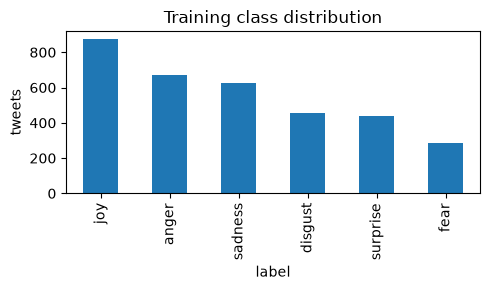

          count  mean   std  min   25%   50%   75%    max
label                                                    
anger     674.0  21.2  37.3  2.0  10.0  15.0  23.8  509.0
disgust   454.0  19.6  29.0  3.0  10.0  15.0  23.0  508.0
fear      288.0  17.9  17.5  3.0  10.0  15.0  22.2  242.0
joy       875.0  21.3  36.5  2.0  10.0  15.0  22.5  508.0
sadness   628.0  18.9  20.7  1.0  10.0  15.0  22.0  387.0
surprise  441.0  15.8   8.7  2.0  10.0  15.0  21.0   79.0


In [56]:
import matplotlib.pyplot as plt

LABELS = ["joy", "anger", "sadness", "disgust", "surprise", "fear"]

fig, ax = plt.subplots(figsize=(5, 3))
train_df["label"].value_counts().reindex(LABELS).plot(kind="bar", ax=ax, color="tab:blue")
ax.set_title("Training class distribution"); ax.set_ylabel("tweets")
plt.tight_layout(); plt.show()

# Tweet length, counted in tokens, summarized per emotion.
train_df["word_count"] = train_df["tokens"].map(len)
print(train_df.groupby("label")["word_count"].describe().round(1))

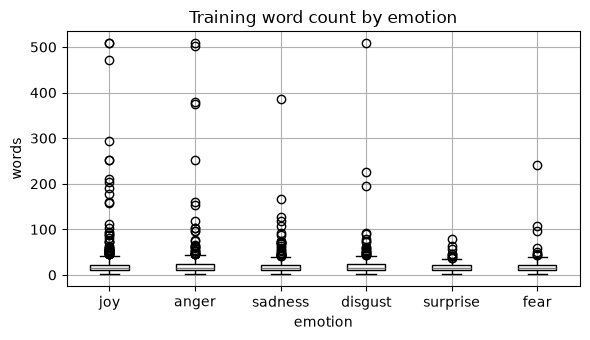

In [57]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 3.5))

sns.boxplot(
    data=train_df,
    x="label",
    y="word_count",
    order=LABELS,
    ax=ax,
    color="white",
    width=0.45,
    boxprops=dict(edgecolor="black", linewidth=1),
    medianprops=dict(color="gray", linewidth=1),
    whiskerprops=dict(color="black", linewidth=1),
    capprops=dict(color="black", linewidth=1),
    flierprops=dict(marker="o", markeredgecolor="black", markerfacecolor="none", markersize=6),
)
ax.set_title("Training word count by emotion")
ax.set_xlabel("emotion")
ax.set_ylabel("words")
ax.grid(True)

plt.tight_layout()
plt.show()

## 3. Model Implementation Steps

In [64]:
### Add the code related to the model implementation steps in cells inside this section
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import LinearSVC

word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

# Fit on train only, then transform test. Use the RAW text, not train_df["clean"].
X_train_tfidf = hstack([word.fit_transform(train_df["text"]),
                        char.fit_transform(train_df["text"])]).tocsr()
X_test_tfidf = hstack([word.transform(test_df["text"]),
                       char.transform(test_df["text"])]).tocsr()

# Tune C with 5-fold CV on the combined features
grid = GridSearchCV(
    LinearSVC(class_weight="balanced", max_iter=10000),
    {"C": [0.03, 0.1, 0.3, 1]},
    scoring="f1_macro",
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
)
grid.fit(X_train_tfidf, y_train)
print(grid.best_params_, round(grid.best_score_, 4))

submission = pd.DataFrame({"post_id": test_df["post_id"],
                           "label": grid.predict(X_test_tfidf)})
submission.to_csv("data/kaggle/submission.csv", index=False)

{'C': 0.1} 0.515
